# Decision Tree – Supervised Learning

Dieses Tutorial zeigt, wie ein Entscheidungsbaum anhand bekannter Iris-Arten lernt und anschließend neue Blumen klassifiziert.


## 1. Datensatz laden

Der Iris-Datensatz enthält 150 Blumen, vier Messwerte pro Blume und die bekannte Art als Label.


In [22]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Iris-Datensatz laden
iris = load_iris()

# X: vier Messwerte pro Blume, y: bekannte Iris-Art
X = iris.data
y = iris.target

print("Merkmale:", iris.feature_names)
print("Arten:", iris.target_names)
print("Anzahl Blumen:", len(X))


Merkmale: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Arten: ['setosa' 'versicolor' 'virginica']
Anzahl Blumen: 150


## 2. Trainings- und Testdaten aufteilen

80 % der Daten werden zum Lernen verwendet, 20 % bleiben für einen unabhängigen Test zurück.


In [41]:
# Mit stratify=y bleiben die drei Arten in beiden Teilmengen gleichmäßig vertreten.
# random_state sorgt dafür, dass die Aufteilung reproduzierbar ist.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Trainingsdaten:", len(X_train))
print("Testdaten:", len(X_test))


Trainingsdaten: 120
Testdaten: 30


## 3. Entscheidungsbaum trainieren

Hier findet das **Supervised Learning** statt: Der Baum lernt Regeln aus den Messwerten und den dazugehörigen bekannten Arten.


In [42]:
# Modell erstellen und trainieren
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

print("Baumtiefe:", model.get_depth())
print("Anzahl Blätter:", model.get_n_leaves())


Baumtiefe: 5
Anzahl Blätter: 8


## 4. Vorhersagen und Genauigkeit

Der Baum erhält die Messwerte der Testblumen, aber nicht deren Arten. Danach vergleichen wir die Vorhersagen mit den echten Labels.


Accuracy: 93.33%


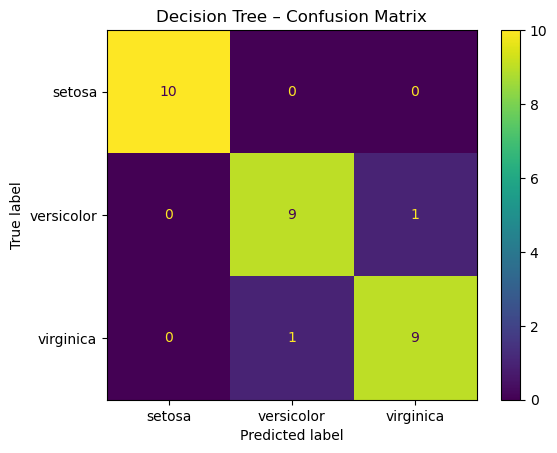

In [43]:
# Vorhersagen für zuvor nicht zum Training verwendete Daten
predictions = model.predict(X_test)

# Anteil korrekt vorhergesagter Iris-Arten
accuracy = accuracy_score(y_test, predictions)
print(f"Accuracy: {accuracy:.2%}")

# Zeigt, welche Arten miteinander verwechselt werden
matrix = confusion_matrix(y_test, predictions)
ConfusionMatrixDisplay(matrix, display_labels=iris.target_names).plot()
plt.title("Decision Tree – Confusion Matrix")
plt.show()


## 5. Eine neue Blume klassifizieren

Die Reihenfolge ist: Sepal Length, Sepal Width, Petal Length, Petal Width (jeweils in cm).


In [44]:
# Neue Blume anhand ihrer vier Messwerte klassifizieren
blume = [[5.1, 4.5, 2.45, 5.2]]
vorhersage = model.predict(blume)[0]
print("Vorhergesagte Iris-Art:", iris.target_names[vorhersage])


Vorhergesagte Iris-Art: versicolor


## 6. Gelernten Entscheidungsbaum darstellen

Die Verzweigungen sind Regeln, die das Modell beim Training selbst ermittelt hat.


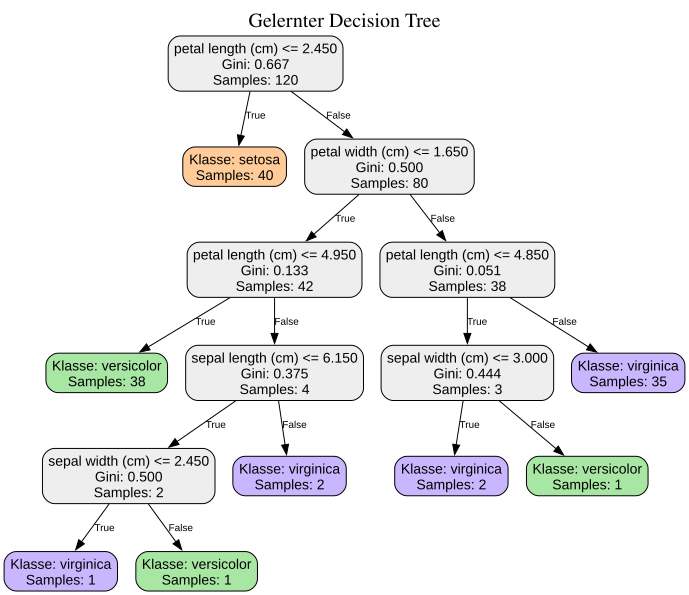

In [45]:
# Entscheidungsregeln des trainierten Modells visualisieren
from decision_tree_plot import plot_decision_tree

plot_decision_tree(
    model,
    iris.feature_names,
    iris.target_names,
    titel="Gelernter Decision Tree",
    #file_name="decision_tree.png"
)